In [1]:
from __future__ import annotations

import argparse
import random
import tempfile
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset


In [2]:
import os
from google.colab import userdata
# Colab > left sidebar > Secrets (key icon): add KAGGLE_USERNAME and KAGGLE_API_TOKEN
os.environ["KAGGLE_USERNAME"] = "manavjadon2006@gmail.com"
os.environ["KAGGLE_API_TOKEN"] = "KGAT_48de8f033e49273d42da4b90380a2f25"

KAGGLE_HANDLE = "awsaf49/cbis-ddsm-breast-cancer-image-dataset"
KAGGLE_INPUT = Path("/kaggle/input/cbis-ddsm-breast-cancer-image-dataset")


def _fetch(rel_path: str) -> str:
    """Local path to ONE file of the dataset (downloads only that file)."""
    if KAGGLE_INPUT.exists():
        return str(KAGGLE_INPUT / rel_path)
    import kagglehub
    return kagglehub.dataset_download(KAGGLE_HANDLE, path=rel_path)

In [3]:
from torchvision.models import (efficientnet_b0, efficientnet_b1,
                                mobilenet_v3_large, EfficientNet_B0_Weights,
                                EfficientNet_B1_Weights, MobileNet_V3_Large_Weights)
import torch.nn as nn

BACKBONE_FEATS = {"efficientnet_b0": 1280, "efficientnet_b1": 1280, "mobilenet_v3_large": 960}


def _backbone(name: str, pretrained: bool):
    if name == "efficientnet_b0":
        return efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
    if name == "efficientnet_b1":
        return efficientnet_b1(weights=EfficientNet_B1_Weights.DEFAULT if pretrained else None)
    if name == "mobilenet_v3_large":
        return mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT if pretrained else None)
    raise ValueError(name)


class MCDropoutHead(nn.Module):
    """Dropout head: MC dropout at inference gives {q_k,t} samples for UQ decomposition."""
    def __init__(self, in_feats: int, p: float):
        super().__init__()
        self.drop = nn.Dropout(p=p)
        self.fc = nn.Linear(in_feats, 1)
        self._p = p

    def forward(self, z):
        return self.fc(self.drop(z)).squeeze(-1)  # logit


class MammoNet(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        bb = _backbone(cfg.backbone, cfg.pretrained)
        self.features = bb.features                      # (B, C, H, W) conv map
        feats = BACKBONE_FEATS[cfg.backbone]
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.head = MCDropoutHead(feats, cfg.dropout_p)
        self.aux_density = nn.Linear(feats, 4) if cfg.aux_density else None
        self.aux_mask = (nn.Sequential(nn.Conv2d(feats, 64, 1), nn.ReLU(inplace=True),
                                       nn.Conv2d(64, 1, 1)) if cfg.aux_mask else None)
        self.cfg = cfg
        self.train_mode_dropout = False

    def forward(self, x, density_target=None, mask_target=None):
        """x: (B, 512, 512). Returns logits dict; MC sampling is applied by the head's dropout."""
        f = self.features(x)
        z = self.global_pool(f).flatten(1)
        logit = self.head(z)
        out = {"logit": logit}
        if self.aux_density is not None:
            out["density_logits"] = self.aux_density(z)
        if self.aux_mask is not None and mask_target is not None:
            m = F.interpolate(self.aux_mask(f), size=mask_target.shape[-2:], mode="bilinear",
                              align_corners=False)
            out["mask_logit"] = m
        return out

    def set_mc_mode(self, enabled: bool):
        """Keep the head in dropout/eval mode so forward() samples from the posterior."""
        self.train_mode_dropout = enabled
        self.eval()
        self.head.drop.train(enabled)


class DeepEnsemble(nn.Module):
    """K-member ensemble. Five members are sufficient for robustness to distribution
    shift and reliably good UQ among sampling-based methods."""
    def __init__(self, cfg):
        super().__init__()
        self.members = nn.ModuleList([MammoNet(cfg) for _ in range(cfg.n_members)])

    def set_mc_mode(self, enabled: bool):
        for m in self.members:
            m.set_mc_mode(enabled)

    def __len__(self):
        return len(self.members)


In [4]:
@dataclass
class Cfg:
    # model
    backbone: str = "efficientnet_b0"
    pretrained: bool = True
    dropout_p: float = 0.3
    aux_density: bool = True
    aux_mask: bool = True
    n_members: int = 1
    # data
    img_size: int = 512
    n_samples: int = 1000
    batch_size: int = 16
    # optimisation
    epochs: int = 50
    lr: float = 1e-4
    weight_decay: float = 1e-4
    w_density: float = 0.2
    w_mask: float = 0.5
    mc_samples: int = 20
    seed: int = 0


class CBISDataset(Dataset):
    def __init__(self, df: pd.DataFrame, img_size: int = 512, train: bool = True):
        self.df = df.reset_index(drop=True)
        self.S = img_size
        self.train = train
        # decode + resize every image ONCE (stored as uint8) instead of re-reading huge JPEGs every epoch
        self._cache = [self._read(r) for r in self.df.to_dict("records")]

    def _read(self, row):
        x = self._load_gray(row["image_path"], Image.BILINEAR)           # (1,S,S) float 0-1
        mask, has_mask = torch.zeros(1, self.S, self.S), 0.0
        mp = row.get("mask_path", None)
        if isinstance(mp, str) and mp and Path(mp).exists():
            mask = (self._load_gray(mp, Image.NEAREST) > 0.5).float()
            has_mask = 1.0
        return (x * 255).round().to(torch.uint8), mask.to(torch.uint8), has_mask

    def __len__(self):
        return len(self.df)

    def _load_gray(self, path, resample):
        img = Image.open(path).convert("L").resize((self.S, self.S), resample)
        return torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).unsqueeze(0)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        x8, m8, has_mask = self._cache[i]                                # already decoded in __init__
        x, mask = x8.float() / 255.0, m8.float()

        if self.train and random.random() < 0.5:                         # h-flip
            x, mask = torch.flip(x, dims=[-1]), torch.flip(mask, dims=[-1])

        x = ((x - 0.449) / 0.226).repeat(3, 1, 1)                        # ImageNet backbones need 3 ch

        d = row.get("density", np.nan)
        density = int(d) - 1 if pd.notna(d) else -100                    # -100 = ignore

        return {
            "image": x,
            "label": torch.tensor(float(row["label"])),
            "density": torch.tensor(density, dtype=torch.long),
            "mask": mask,
            "has_mask": torch.tensor(has_mask),
        }


def pick_subset(df: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """Take n rows, balanced across classes when possible."""
    per = max(1, n // df["label"].nunique())
    parts = [g.sample(min(per, len(g)), random_state=seed) for _, g in df.groupby("label")]
    return pd.concat(parts).head(n).reset_index(drop=True)

In [5]:
def make_cbis_manifest(n: int = 4, kind: str = "mass", seed: int = 0, split: str = "train") -> pd.DataFrame:
    """split = 'train' or 'test' -> official CBIS-DDSM split (patients do not overlap between the two)."""
    info = (pd.read_csv(_fetch("csv/dicom_info.csv"))
              .drop_duplicates("SeriesInstanceUID").set_index("SeriesInstanceUID"))

    rows = pd.read_csv(_fetch(f"csv/{kind}_case_description_{split}_set.csv"))
    rows.columns = [c.strip().replace(" ", "_") for c in rows.columns]   # image_file_path, breast_density, ...
    rows["label"] = (rows["pathology"].str.upper() == "MALIGNANT").astype(int)

    def series_file(path_val, wanted_desc):
        """JPEG path (relative to dataset root) if this series has the wanted description."""
        uid = str(path_val).strip().split("/")[2]
        if uid in info.index and info.loc[uid, "SeriesDescription"] == wanted_desc:
            return info.loc[uid, "image_path"].replace("CBIS-DDSM/", "", 1)
        return None

    data = []
    for _, row in rows.iterrows():
        img = series_file(row["image_file_path"], "full mammogram images")
        if img is None:
            continue
        mask = next((m for m in (series_file(row[c], "ROI mask images")
                                 for c in ("ROI_mask_file_path", "cropped_image_file_path"))
                     if m), None)
        d = row["breast_density"]
        data.append({"image_path": img, "label": row["label"],
                     "density": d if d in (1, 2, 3, 4) else np.nan,
                     "mask_path": mask})

    data = pd.DataFrame(data).drop_duplicates("image_path")      # one mammogram can appear in several ROI rows
    data = pick_subset(data, n, seed)                            # class-balanced pick BEFORE downloading anything

    data["image_path"] = data["image_path"].map(_fetch)
    data["mask_path"] = data["mask_path"].map(lambda m: _fetch(m) if isinstance(m, str) else None)
    return data

In [6]:
def compute_loss(out: dict, batch: dict, cfg: Cfg):
    cls = F.binary_cross_entropy_with_logits(out["logit"], batch["label"])
    loss, logs = cls, {"cls": cls.item()}

    if "density_logits" in out and (batch["density"] != -100).any():
        d = F.cross_entropy(out["density_logits"], batch["density"], ignore_index=-100)
        loss = loss + cfg.w_density * d
        logs["density"] = d.item()

    if "mask_logit" in out and batch["has_mask"].sum() > 0:
        per_px = F.binary_cross_entropy_with_logits(out["mask_logit"], batch["mask"],
                                                    reduction="none")
        per_sample = per_px.flatten(1).mean(1)
        m = (per_sample * batch["has_mask"]).sum() / batch["has_mask"].sum().clamp(min=1)
        loss = loss + cfg.w_mask * m
        logs["mask"] = m.item()

    return loss, logs

In [7]:
def train(models, loader, cfg: Cfg, device):
    opts = [torch.optim.AdamW(m.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
            for m in models]

    for epoch in range(1, cfg.epochs + 1):
        for m in models:
            m.train()
        tot_loss, tot_correct, n = 0.0, 0, 0

        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            for m, opt in zip(models, opts):          # each ensemble member trains independently
                opt.zero_grad(set_to_none=True)
                out = m(batch["image"], mask_target=batch["mask"] if cfg.aux_mask else None)
                loss, _ = compute_loss(out, batch, cfg)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0)
                opt.step()

                tot_loss += loss.item() * len(batch["label"])
                tot_correct += ((out["logit"] > 0).float() == batch["label"]).sum().item()
                n += len(batch["label"])

        print(f"epoch {epoch}/{cfg.epochs}  loss={tot_loss / n:.4f}  acc={tot_correct / n:.3f}")

@torch.no_grad()
def mc_predict(models, x, T: int):
    """Returns (mean_prob, std_prob) over K members x T MC-dropout samples."""
    samples = []
    for m in models:
        m.set_mc_mode(True)                           # eval() everywhere except head dropout
        samples += [torch.sigmoid(m(x)["logit"]) for _ in range(T)]
    s = torch.stack(samples)                          # (K*T, B)
    return s.mean(0), s.std(0)

In [8]:
cfg = Cfg()
random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

df = make_cbis_manifest(n=cfg.n_samples, kind="mass", seed=cfg.seed, split="train")   # balanced, official train split
print(f"Loaded {len(df)} samples, label counts: {df['label'].value_counts().to_dict()}")

loader = DataLoader(CBISDataset(df, cfg.img_size, train=True),
                    batch_size=cfg.batch_size, shuffle=True)

model = DeepEnsemble(cfg) if cfg.n_members > 1 else MammoNet(cfg)
models = list(model.members) if isinstance(model, DeepEnsemble) else [model]
for m in models:
    m.to(device)

train(models, loader, cfg, device)

torch.save([m.state_dict() for m in models], "mammonet_smoke.pt")

Using Colab cache for faster access to the 'cbis-ddsm-breast-cancer-image-dataset' dataset.
Loaded 1000 samples, label counts: {0: 500, 1: 500}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 150MB/s]


epoch 1/50  loss=1.1206  acc=0.583
epoch 2/50  loss=0.8985  acc=0.701
epoch 3/50  loss=0.7602  acc=0.768
epoch 4/50  loss=0.6498  acc=0.803
epoch 5/50  loss=0.5591  acc=0.850
epoch 6/50  loss=0.4957  acc=0.877
epoch 7/50  loss=0.4490  acc=0.894
epoch 8/50  loss=0.3909  acc=0.911
epoch 9/50  loss=0.3603  acc=0.929
epoch 10/50  loss=0.3507  acc=0.922
epoch 11/50  loss=0.3185  acc=0.940
epoch 12/50  loss=0.2836  acc=0.954
epoch 13/50  loss=0.2309  acc=0.958
epoch 14/50  loss=0.2670  acc=0.950
epoch 15/50  loss=0.2242  acc=0.961
epoch 16/50  loss=0.2340  acc=0.959
epoch 17/50  loss=0.2070  acc=0.960
epoch 18/50  loss=0.1874  acc=0.967
epoch 19/50  loss=0.1710  acc=0.971
epoch 20/50  loss=0.1332  acc=0.984
epoch 21/50  loss=0.1625  acc=0.972
epoch 22/50  loss=0.1232  acc=0.981
epoch 23/50  loss=0.1559  acc=0.973
epoch 24/50  loss=0.1181  acc=0.981
epoch 25/50  loss=0.1269  acc=0.976
epoch 26/50  loss=0.0831  acc=0.987
epoch 27/50  loss=0.1025  acc=0.982
epoch 28/50  loss=0.1145  acc=0.976
e

In [9]:
df

,image_path,label,density,mask_path
0,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,0,2,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
1,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,0,3,None
2,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,0,4,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
3,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,0,1,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
4,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,0,2,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
...,...,...,...,...
995,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,1,2,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
996,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,1,2,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
997,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,1,4,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
998,/kaggle/input/cbis-ddsm-breast-cancer-image-da...,1,2,/kaggle/input/cbis-ddsm-breast-cancer-image-da...


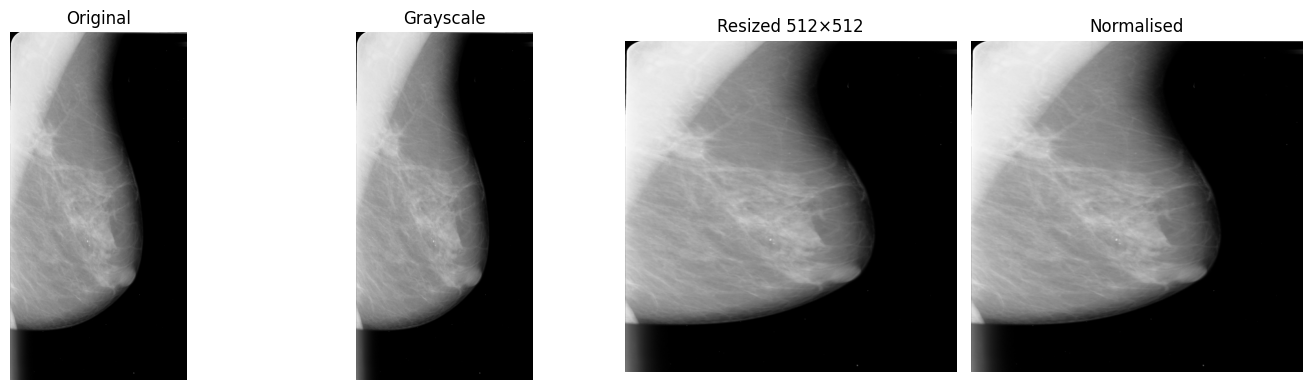

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

MEAN, STD = 0.449, 0.226

def show_preprocessing(image_path, img_size=None, save="preprocessing_views.png"):
    S = img_size or cfg.img_size
    orig = Image.open(image_path)
    gray = orig.convert("L")
    resized = gray.resize((S, S), Image.BILINEAR)
    norm = (np.asarray(resized, dtype=np.float32) / 255.0 - MEAN) / STD

    panels = [(np.asarray(orig.convert("L")), "Original"),
              (np.asarray(gray), "Grayscale"),
              (np.asarray(resized), f"Resized {S}×{S}"),
              (norm, "Normalised")]
    fig, ax = plt.subplots(1, 4, figsize=(14, 4))
    for a, (im, title) in zip(ax, panels):
        a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
    fig.tight_layout()
    if save: fig.savefig(save, dpi=300)
    plt.show()


img_path = "/kaggle/input/cbis-ddsm-breast-cancer-image-dataset/jpeg/1.3.6.1.4.1.9590.100.1.2.295967619312101214807652573813097665333/1-073.jpg"
show_preprocessing(img_path)

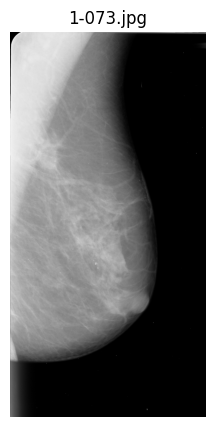

P(malignant) = 1.000 ± 0.000
Prediction  : MALIGNANT
Density     : 2 (conf 1.00)


(1.0, 0.0)

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = Cfg()
cfg.pretrained = False
models = [MammoNet(cfg).to(device) for _ in range(cfg.n_members)]
for m, sd in zip(models, torch.load("mammonet_smoke.pt", map_location=device)):
    m.load_state_dict(sd)


@torch.no_grad()
def predict_image(image_path: str, T: int = 20, threshold: float = 0.5):
    img = Image.open(image_path).convert("L")
    plt.figure(figsize=(5, 5))
    plt.imshow(img, cmap="gray")
    plt.title(Path(image_path).name)
    plt.axis("off")
    plt.show()

    x = img.resize((cfg.img_size, cfg.img_size), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(x, dtype=np.float32) / 255.0).unsqueeze(0)   # (1,H,W)
    x = ((x - 0.449) / 0.226).repeat(3, 1, 1).unsqueeze(0).to(device)            # (1,3,H,W)

    mean, std = mc_predict(models, x, T)
    p, s = mean.item(), std.item()

    print(f"P(malignant) = {p:.3f} ± {s:.3f}")
    print("Prediction  :", "MALIGNANT" if p >= threshold else "BENIGN")

    if cfg.aux_density:
        dens = models[0](x)["density_logits"].softmax(-1)[0]
        print("Density     :", int(dens.argmax()) + 1, f"(conf {dens.max():.2f})")

    return p, s

predict_image("/kaggle/input/cbis-ddsm-breast-cancer-image-dataset/jpeg/1.3.6.1.4.1.9590.100.1.2.295967619312101214807652573813097665333/1-073.jpg")

## Held-out test evaluation
Everything below is computed on images from the official CBIS-DDSM **test** split (different patients from training). Change `N_TEST` to use more images.

In [12]:
# ---------- Inference helper: everything we need per image, computed once ----------
@torch.no_grad()
def predict_full(models, batch, T: int = 20, bs: int = 8):
    """MC-dropout (+ ensemble) predictions for a whole test batch, processed `bs` images at a time.

    Returns numpy arrays:
      p, s        mean / std of P(malignant) over K*T samples (same meaning as mc_predict)
      H_total     predictive entropy of the mean prediction                 (nats, max = ln2 = 0.693)
      H_alea      mean entropy of the individual samples  -> aleatoric (data) uncertainty
      H_epi       H_total - H_alea (mutual information)   -> epistemic (model) uncertainty
      dens_pred   predicted BI-RADS density 1-4 (auxiliary head)
      mask_prob   (N, S, S) predicted lesion-probability map (auxiliary head)
    """
    N, S = len(batch["label"]), batch["image"].shape[-1]
    samples, dens, masks = [], [], []
    for i in range(0, N, bs):
        x = batch["image"][i:i + bs].to(device)

        chunk = []
        for m in models:
            m.set_mc_mode(True)                                   # dropout ON in the head only
            z = m.global_pool(m.features(x)).flatten(1)           # backbone runs once per member
            chunk += [torch.sigmoid(m.head(z)) for _ in range(T)]
        samples.append(torch.stack(chunk).cpu())                  # (K*T, b)

        m0 = models[0]; m0.set_mc_mode(False)                     # deterministic auxiliary heads
        f = m0.features(x); z0 = m0.global_pool(f).flatten(1)
        dens.append((m0.aux_density(z0).argmax(1) + 1).cpu() if m0.aux_density is not None
                    else torch.zeros(len(x), dtype=torch.long))
        if m0.aux_mask is not None:
            mk = F.interpolate(m0.aux_mask(f), size=(S, S), mode="bilinear", align_corners=False)
            masks.append(torch.sigmoid(mk)[:, 0].cpu())
        else:
            masks.append(torch.zeros(len(x), S, S))

    P = torch.cat(samples, dim=1).numpy()                         # (K*T, N)
    mean, std = P.mean(0), P.std(0, ddof=1)
    Hb = lambda q: -(q * np.log(q + 1e-12) + (1 - q) * np.log(1 - q + 1e-12))
    H_total, H_alea = Hb(mean), Hb(P).mean(0)
    return dict(p=mean, s=std, H_total=H_total, H_alea=H_alea,
                H_epi=np.maximum(H_total - H_alea, 0),
                dens_pred=torch.cat(dens).numpy(), mask_prob=torch.cat(masks).numpy())

In [13]:
# ---------- Held-out TEST set: official CBIS-DDSM *test* split (patients never seen in training) ----------
N_TEST = 200         # 100 benign + 100 malignant if the test split has that many; everything below adapts
test_df = make_cbis_manifest(n=N_TEST, kind="mass", seed=cfg.seed, split="test")
print(f"Test images: {len(test_df)} | label counts: {test_df['label'].value_counts().to_dict()}")

loader = DataLoader(CBISDataset(test_df, cfg.img_size, train=False),
                    batch_size=cfg.batch_size, shuffle=False)
chunks = list(loader)
eval_batch = {k: torch.cat([b[k] for b in chunks]) for k in chunks[0]}

torch.manual_seed(cfg.seed)
pf = predict_full(models, eval_batch, T=cfg.mc_samples)           # all per-image predictions, once
p, s = torch.tensor(pf["p"]), torch.tensor(pf["s"])              # same names the metric cells below use
y_true = eval_batch["label"]

for i in range(len(test_df)):
    print(f"image {i}: label={int(y_true[i])}  p_malignant={p[i]:.3f} ± {s[i]:.3f}")

Test images: 200 | label counts: {0: 100, 1: 100}
image 0: label=0  p_malignant=0.963 ± 0.009
image 1: label=0  p_malignant=0.000 ± 0.000
image 2: label=0  p_malignant=0.017 ± 0.003
image 3: label=0  p_malignant=0.001 ± 0.000
image 4: label=0  p_malignant=0.001 ± 0.000
image 5: label=0  p_malignant=0.000 ± 0.000
image 6: label=0  p_malignant=0.000 ± 0.000
image 7: label=0  p_malignant=0.000 ± 0.000
image 8: label=0  p_malignant=1.000 ± 0.000
image 9: label=0  p_malignant=0.000 ± 0.000
image 10: label=0  p_malignant=0.004 ± 0.001
image 11: label=0  p_malignant=0.002 ± 0.000
image 12: label=0  p_malignant=0.000 ± 0.000
image 13: label=0  p_malignant=0.000 ± 0.000
image 14: label=0  p_malignant=0.000 ± 0.000
image 15: label=0  p_malignant=0.000 ± 0.000
image 16: label=0  p_malignant=0.823 ± 0.020
image 17: label=0  p_malignant=0.012 ± 0.002
image 18: label=0  p_malignant=0.000 ± 0.000
image 19: label=0  p_malignant=0.238 ± 0.040
image 20: label=0  p_malignant=0.735 ± 0.023
image 21: label

In [14]:
import numpy as np
import pandas as pd


def _np(a):
    if hasattr(a, "detach"):
        a = a.detach().cpu().numpy()
    return np.asarray(a, dtype=float)


def find_thresholds(s, p, y, sens_floor=0.95, threshold=0.5, arb_q=0.995):
    """
    t0 : uncertainty cut-off for AUTO-reading. Exams with u <= t0 are decided by the model;
         chosen as the largest t0 whose system sensitivity stays >= sens_floor.
    t1 : uncertainty cut-off for ARBITRATION. Exams with u > t1 (top 0.5% by default) go to
         arbitration; t0 < u <= t1 go to routine radiologist reading.
    """
    p, s, y = _np(p), _np(s), _np(y)
    pred, order, n_pos = p >= threshold, np.argsort(s), max((y == 1).sum(), 1)
    best_k = 0
    for k in range(1, len(y) + 1):
        auto = np.zeros(len(y), bool); auto[order[:k]] = True
        tp = (auto & pred & (y == 1)).sum() + ((~auto) & (y == 1)).sum()
        if tp / n_pos >= sens_floor:
            best_k = k
    t0 = s[order[best_k - 1]] if best_k > 0 else -np.inf
    t1 = max(np.quantile(s, arb_q), t0)
    return float(t0), float(t1)


def ece_score(p, y, n_bins=10):
    p, y = _np(p), _np(y)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    return float(sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean())
                     for b in range(n_bins) if (idx == b).any()))


def endpoint_metrics(p, s, y, sens_floor=0.95, threshold=0.5):
    """
    Assumption: exams NOT auto-read (u > t0) are handled by radiologists who recall exactly
    the true cancers (same assumption as your pareto_table).
    """
    p, s, y = _np(p), _np(s), _np(y)
    N, n_pos = len(y), max((y == 1).sum(), 1)
    t0, t1 = find_thresholds(s, p, y, sens_floor, threshold)

    auto = s <= t0
    pred = p >= threshold
    missed = auto & ~pred & (y == 1)                      # cancers auto-read as benign
    detected = (auto & pred & (y == 1)).sum() + ((~auto) & (y == 1)).sum()
    recalled = (auto & pred).sum() + ((~auto) & (y == 1)).sum()

    return {
        "Workload Reduction (%)":        100 * auto.mean(),
        "Missed Cancer Rate (%)":        100 * missed.sum() / n_pos,
        "Recall Rate (%)":               100 * recalled / N,
        "CDR (cancers per 1000 exams)":  1000 * detected / N,
        "Sensitivity (%)":               100 * detected / n_pos,
        "ECE":                           ece_score(p, y),
        "Uncertainty t0 (auto-read)":    t0,
    }


y_true = eval_batch["label"]
report = pd.DataFrame({"value": endpoint_metrics(p, s, y_true, sens_floor=0.95)})
print(report.to_string(float_format=lambda v: f"{v:.4f}"))
report.to_csv("endpoint_metrics.csv")

                                value
Workload Reduction (%)        46.0000
Missed Cancer Rate (%)         5.0000
Recall Rate (%)               50.0000
CDR (cancers per 1000 exams) 475.0000
Sensitivity (%)               95.0000
ECE                            0.2271
Uncertainty t0 (auto-read)     0.0001


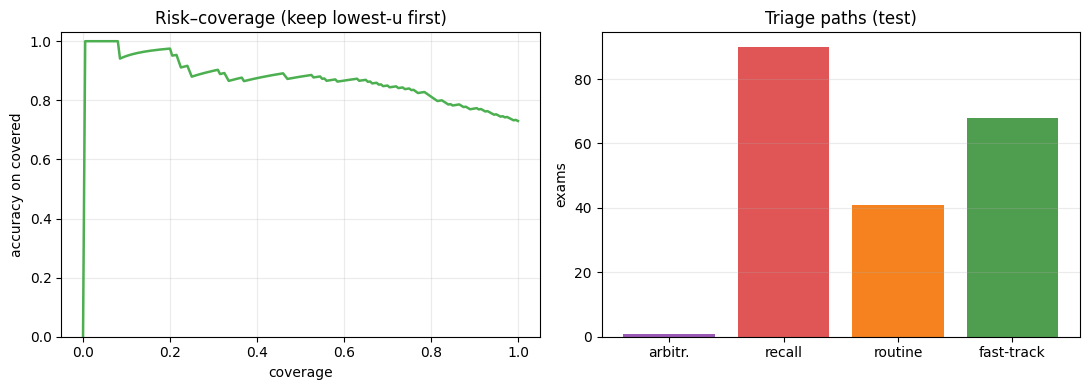

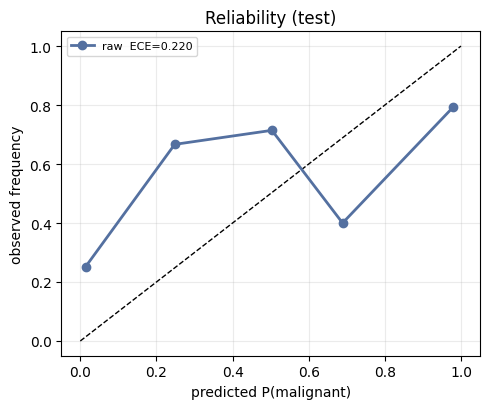

In [15]:
import numpy as np
import matplotlib.pyplot as plt


def _np(a):
    if hasattr(a, "detach"):
        a = a.detach().cpu().numpy()
    return np.asarray(a, dtype=float)


def risk_coverage_acc(u, p, y, threshold=0.5):
    u, p, y = _np(u), _np(p), _np(y)
    order = np.argsort(u)
    correct = ((p >= threshold).astype(float) == y)[order]
    k = np.arange(1, len(y) + 1)
    cov = np.concatenate([[0.0], k / len(y)])
    acc = np.concatenate([[0.0], np.cumsum(correct) / k])
    return cov, acc


def triage(u, p, u_hi_q=0.995, u_lo_q=0.60, p_recall=0.5, p_fast=0.25):

    u, p = _np(u), _np(p)
    u_hi, u_lo = np.quantile(u, u_hi_q), np.quantile(u, u_lo_q)
    path = np.full(len(p), "routine", dtype=object)
    path[(p <= p_fast) & (u <= u_lo)] = "fast-track"
    path[p >= p_recall] = "recall"
    path[u > u_hi] = "arbitration"          # highest priority
    return path


def reliability_bins(p, y, n_bins=5):
    p, y = _np(p), _np(y)
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    mp, of, n = [], [], []
    for b in range(n_bins):
        m = idx == b
        if m.any():
            mp.append(p[m].mean()); of.append(y[m].mean()); n.append(int(m.sum()))
    mp, of, n = map(np.array, (mp, of, n))
    ece = (np.abs(of - mp) * n).sum() / n.sum()
    return mp, of, n, float(ece)


def plot_risk_and_triage(u, p, y, path=None, split="test"):
    cov, acc = risk_coverage_acc(u, p, y)
    path_arr = triage(u, p)
    names = ["arbitr.", "recall", "routine", "fast-track"]
    keys = ["arbitration", "recall", "routine", "fast-track"]
    colors = ["#9b59b6", "#e05555", "#f5821f", "#4f9d4f"]
    counts = [(path_arr == k).sum() for k in keys]

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(cov, acc, color="#4caf50", lw=1.8)
    ax[0].set_title("Risk–coverage (keep lowest-u first)")
    ax[0].set_xlabel("coverage"); ax[0].set_ylabel("accuracy on covered")
    ax[0].set_xlim(-0.05, 1.05); ax[0].set_ylim(0, 1.03); ax[0].grid(alpha=0.25)

    ax[1].bar(names, counts, color=colors)
    ax[1].set_title(f"Triage paths ({split})"); ax[1].set_ylabel("exams")
    ax[1].grid(alpha=0.25, axis="y")
    fig.tight_layout()
    if path: fig.savefig(path, dpi=300)
    plt.show()
    return dict(zip(keys, counts))


def plot_reliability_curve(p, y, n_bins=5, path=None, split="test"):
    mp, of, n, ece = reliability_bins(p, y, n_bins)
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.plot(mp, of, "o-", color="#5470a0", lw=2, label=f"raw  ECE={ece:.3f}")
    ax.set_xlabel("predicted P(malignant)"); ax.set_ylabel("observed frequency")
    ax.set_title(f"Reliability ({split})")
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.25); ax.legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    if path: fig.savefig(path, dpi=300)
    plt.show()


y_true = eval_batch["label"]
plot_risk_and_triage(u=s, p=p, y=y_true, path="risk_triage.png")
plot_reliability_curve(p, y_true, n_bins=5 if len(y_true) >= 50 else 3, path="reliability.png")

## Extended test metrics
Accuracy, sensitivity/specificity, ROC-AUC, PR-AUC, MCC, Brier, log-loss, ECE with 95% bootstrap CIs, uncertainty quality and the auxiliary density head.

In [16]:
# ===================== EXTENDED TEST METRICS (with 95% bootstrap CIs) =====================
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, f1_score, matthews_corrcoef, brier_score_loss, log_loss)

THR = 0.5
y_np, p_np, s_np = _np(y_true).astype(int), _np(p), _np(s)
pred_np = (p_np >= THR).astype(int)
correct = pred_np == y_np


def _div(a, b):
    return a / b if b else np.nan


def clf_metrics(p, y, thr=0.5):
    pr = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pr, labels=[0, 1]).ravel()
    sens, spec = _div(tp, tp + fn), _div(tn, tn + fp)
    two = len(np.unique(y)) == 2
    return {
        "Accuracy": (tp + tn) / len(y),
        "Balanced accuracy": np.nanmean([sens, spec]),
        "Sensitivity (recall)": sens,
        "Specificity": spec,
        "Precision (PPV)": _div(tp, tp + fp),
        "NPV": _div(tn, tn + fn),
        "F1": f1_score(y, pr, zero_division=0),
        "MCC": matthews_corrcoef(y, pr),
        "ROC-AUC": roc_auc_score(y, p) if two else np.nan,
        "PR-AUC (avg. precision)": average_precision_score(y, p) if two else np.nan,
        "Brier score": brier_score_loss(y, p),
        "Log loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1]),
        "ECE": ece_score(p, y),
    }


def bootstrap_ci(p, y, thr=0.5, n_boot=1000, seed=0):
    """Percentile 95% CI by resampling test images with replacement."""
    keys = ["Accuracy", "Sensitivity (recall)", "Specificity", "ROC-AUC", "PR-AUC (avg. precision)"]
    rng, n, store = np.random.default_rng(seed), len(y), {k: [] for k in keys}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yy, pi = y[idx], p[idx]
        if len(np.unique(yy)) < 2:
            continue
        pr = (pi >= thr).astype(int)
        store["Accuracy"].append((pr == yy).mean())
        store["Sensitivity (recall)"].append((pr[yy == 1] == 1).mean())
        store["Specificity"].append((pr[yy == 0] == 0).mean())
        store["ROC-AUC"].append(roc_auc_score(yy, pi))
        store["PR-AUC (avg. precision)"].append(average_precision_score(yy, pi))
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) if v else (np.nan, np.nan)
            for k, v in store.items()}


metrics = clf_metrics(p_np, y_np, THR)
ci = bootstrap_ci(p_np, y_np, THR)
test_metrics = pd.DataFrame(
    [{"metric": k, "value": v, "95% CI low": ci.get(k, (np.nan, np.nan))[0],
      "95% CI high": ci.get(k, (np.nan, np.nan))[1]} for k, v in metrics.items()]).set_index("metric")
tn, fp, fn, tp = confusion_matrix(y_np, pred_np, labels=[0, 1]).ravel()

print(f"n = {len(y_np)} test images  ({(y_np == 1).sum()} malignant / {(y_np == 0).sum()} benign),  threshold = {THR}")
print(f"TP={tp}  FP={fp}  TN={tn}  FN={fn}\n")
print(test_metrics.to_string(float_format=lambda v: f"{v:.3f}"))
test_metrics.to_csv("test_metrics.csv")

# ---- how trustworthy is the model's uncertainty? ----
order = np.argsort(s_np)
half = len(order) // 2
err = ~correct
unc = {
    "Mean std - correct predictions":            s_np[correct].mean() if correct.any() else np.nan,
    "Mean std - wrong predictions":              s_np[err].mean() if err.any() else np.nan,
    "Error-detection AUC (uncertainty -> error)": roc_auc_score(err, s_np) if 0 < err.sum() < len(err) else np.nan,
    "Accuracy, 50% most certain images":         correct[order[:max(half, 1)]].mean(),
    "Accuracy, 50% least certain images":        correct[order[half:]].mean() if len(order) > 1 else np.nan,
    "Mean aleatoric entropy (nats)":             pf["H_alea"].mean(),
    "Mean epistemic entropy / MI (nats)":        pf["H_epi"].mean(),
}
print("\nUncertainty quality")
print(pd.Series(unc).to_string(float_format=lambda v: f"{v:.4f}"))

# ---- auxiliary breast-density head ----
dens_true = _np(eval_batch["density"]).astype(int)          # -100 = density unknown
has_d = dens_true != -100
dens_acc = ((pf["dens_pred"] - 1) == dens_true)[has_d].mean() if has_d.any() else np.nan
print(f"\nDensity head accuracy: {dens_acc:.3f}  (on {has_d.sum()} images with a density label)")

n = 200 test images  (100 malignant / 100 benign),  threshold = 0.5
TP=68  FP=22  TN=78  FN=32

                         value  95% CI low  95% CI high
metric                                                 
Accuracy                 0.730       0.670        0.795
Balanced accuracy        0.730         NaN          NaN
Sensitivity (recall)     0.680       0.593        0.771
Specificity              0.780       0.698        0.861
Precision (PPV)          0.756         NaN          NaN
NPV                      0.709         NaN          NaN
F1                       0.716         NaN          NaN
MCC                      0.462         NaN          NaN
ROC-AUC                  0.839       0.783        0.893
PR-AUC (avg. precision)  0.826       0.749        0.896
Brier score              0.226         NaN          NaN
Log loss                 1.317         NaN          NaN
ECE                      0.227         NaN          NaN

Uncertainty quality
Mean std - correct predictions             

## Performance dashboard
ROC, precision-recall, confusion matrix, per-image probabilities, class separation, uncertainty vs correctness.

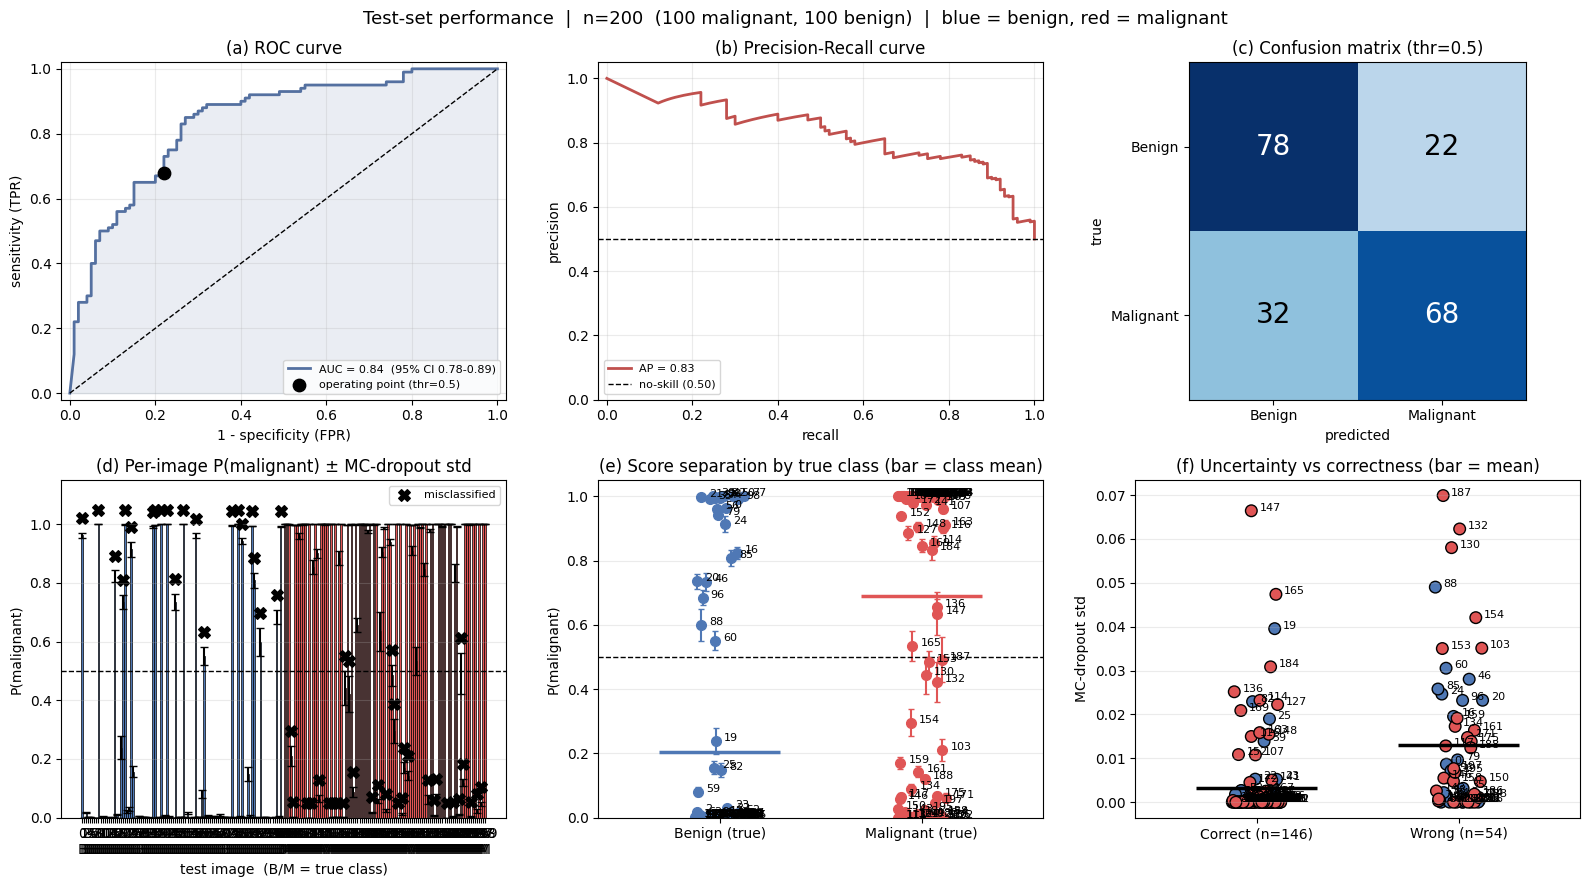

In [17]:
# ===================== PLOTS 1: PERFORMANCE DASHBOARD =====================
C_B, C_M = "#4f78b5", "#e05555"          # benign / malignant colours


def plot_dashboard(p, y, s, thr=0.5, ci=None, path=None):
    pred = (p >= thr).astype(int); ok = pred == y; n = len(y); two = len(np.unique(y)) == 2
    cols = np.where(y == 1, C_M, C_B)
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(2, 3, figsize=(16, 9))

    # (a) ROC
    a = ax[0, 0]
    if two:
        fpr, tpr, _ = roc_curve(y, p)
        lab = f"AUC = {roc_auc_score(y, p):.2f}"
        if ci: lab += f"  (95% CI {ci['ROC-AUC'][0]:.2f}-{ci['ROC-AUC'][1]:.2f})"
        a.plot(fpr, tpr, color="#5470a0", lw=2, label=lab)
        a.fill_between(fpr, tpr, alpha=0.12, color="#5470a0")
        a.scatter([((pred == 1) & (y == 0)).sum() / (y == 0).sum()],
                  [((pred == 1) & (y == 1)).sum() / (y == 1).sum()],
                  s=80, c="k", zorder=5, label=f"operating point (thr={thr})")
        a.legend(loc="lower right", fontsize=8)
    else:
        a.text(0.5, 0.5, "needs both classes", ha="center")
    a.plot([0, 1], [0, 1], "k--", lw=1)
    a.set(title="(a) ROC curve", xlabel="1 - specificity (FPR)", ylabel="sensitivity (TPR)",
          xlim=(-0.02, 1.02), ylim=(-0.02, 1.02)); a.grid(alpha=0.25)

    # (b) Precision-Recall
    a = ax[0, 1]
    if two:
        pr_, rc_, _ = precision_recall_curve(y, p)
        a.plot(rc_, pr_, color="#c0504d", lw=2, label=f"AP = {average_precision_score(y, p):.2f}")
        a.axhline(y.mean(), color="k", ls="--", lw=1, label=f"no-skill ({y.mean():.2f})")
        a.legend(loc="lower left", fontsize=8)
    else:
        a.text(0.5, 0.5, "needs both classes", ha="center")
    a.set(title="(b) Precision-Recall curve", xlabel="recall", ylabel="precision",
          xlim=(-0.02, 1.02), ylim=(0, 1.05)); a.grid(alpha=0.25)

    # (c) Confusion matrix
    a = ax[0, 2]
    cm = confusion_matrix(y, pred, labels=[0, 1])
    a.imshow(cm, cmap="Blues", vmin=0)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=20,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1], ["Benign", "Malignant"]); a.set_yticks([0, 1], ["Benign", "Malignant"])
    a.set(title=f"(c) Confusion matrix (thr={thr})", xlabel="predicted", ylabel="true")

    # (d) per-image probability +/- MC std
    a = ax[1, 0]
    a.bar(np.arange(n), p, yerr=s, color=cols, capsize=3, edgecolor="k", lw=0.5)
    a.axhline(thr, color="k", ls="--", lw=1)
    if (~ok).any():
        w = np.where(~ok)[0]
        a.scatter(w, np.minimum(p[w] + s[w], 1) + 0.05, marker="X", s=70, c="k", label="misclassified")
        a.legend(fontsize=8, loc="upper right")
    a.set_xticks(range(n), [f"{i}\n{'M' if y[i] else 'B'}" for i in range(n)])
    a.set(title="(d) Per-image P(malignant) ± MC-dropout std", xlabel="test image  (B/M = true class)",
          ylabel="P(malignant)", ylim=(0, 1.15)); a.grid(alpha=0.25, axis="y")

    # (e) probability by true class
    a = ax[1, 1]
    for c, col in ((0, C_B), (1, C_M)):
        idx = np.where(y == c)[0]
        if not len(idx): continue
        xj = c + rng.uniform(-0.12, 0.12, len(idx))
        a.errorbar(xj, p[idx], yerr=s[idx], fmt="o", color=col, capsize=2, ms=7)
        a.hlines(p[idx].mean(), c - 0.3, c + 0.3, color=col, lw=2.5)
        for xi, pi, ii in zip(xj, p[idx], idx): a.text(xi + 0.04, pi, str(ii), fontsize=8)
    a.axhline(thr, color="k", ls="--", lw=1)
    a.set_xticks([0, 1], ["Benign (true)", "Malignant (true)"]); a.set_xlim(-0.6, 1.6)
    a.set(title="(e) Score separation by true class (bar = class mean)", ylabel="P(malignant)", ylim=(0, 1.05))
    a.grid(alpha=0.25, axis="y")

    # (f) uncertainty vs correctness
    a = ax[1, 2]
    for k, mask in enumerate((ok, ~ok)):
        idx = np.where(mask)[0]
        if not len(idx): continue
        xj = k + rng.uniform(-0.12, 0.12, len(idx))
        a.scatter(xj, s[idx], c=cols[idx], edgecolor="k", s=70)
        a.hlines(s[idx].mean(), k - 0.3, k + 0.3, color="k", lw=2.5)
        for xi, si, ii in zip(xj, s[idx], idx): a.text(xi + 0.04, si, str(ii), fontsize=8)
    if not (~ok).any(): a.text(1, s.mean(), "no wrong predictions", ha="center", color="gray")
    a.set_xticks([0, 1], [f"Correct (n={ok.sum()})", f"Wrong (n={(~ok).sum()})"]); a.set_xlim(-0.6, 1.6)
    a.set(title="(f) Uncertainty vs correctness (bar = mean)", ylabel="MC-dropout std"); a.grid(alpha=0.25, axis="y")

    fig.suptitle(f"Test-set performance  |  n={n}  ({(y == 1).sum()} malignant, {(y == 0).sum()} benign)  |  "
                 f"blue = benign, red = malignant", fontsize=13)
    fig.tight_layout()
    if path: fig.savefig(path, dpi=300)
    plt.show()


plot_dashboard(p_np, y_np, s_np, THR, ci=ci, path="test_dashboard.png")

## Image gallery & lesion localisation
Each test image with its prediction, plus the auxiliary mask head's predicted lesion map against the ground-truth ROI.

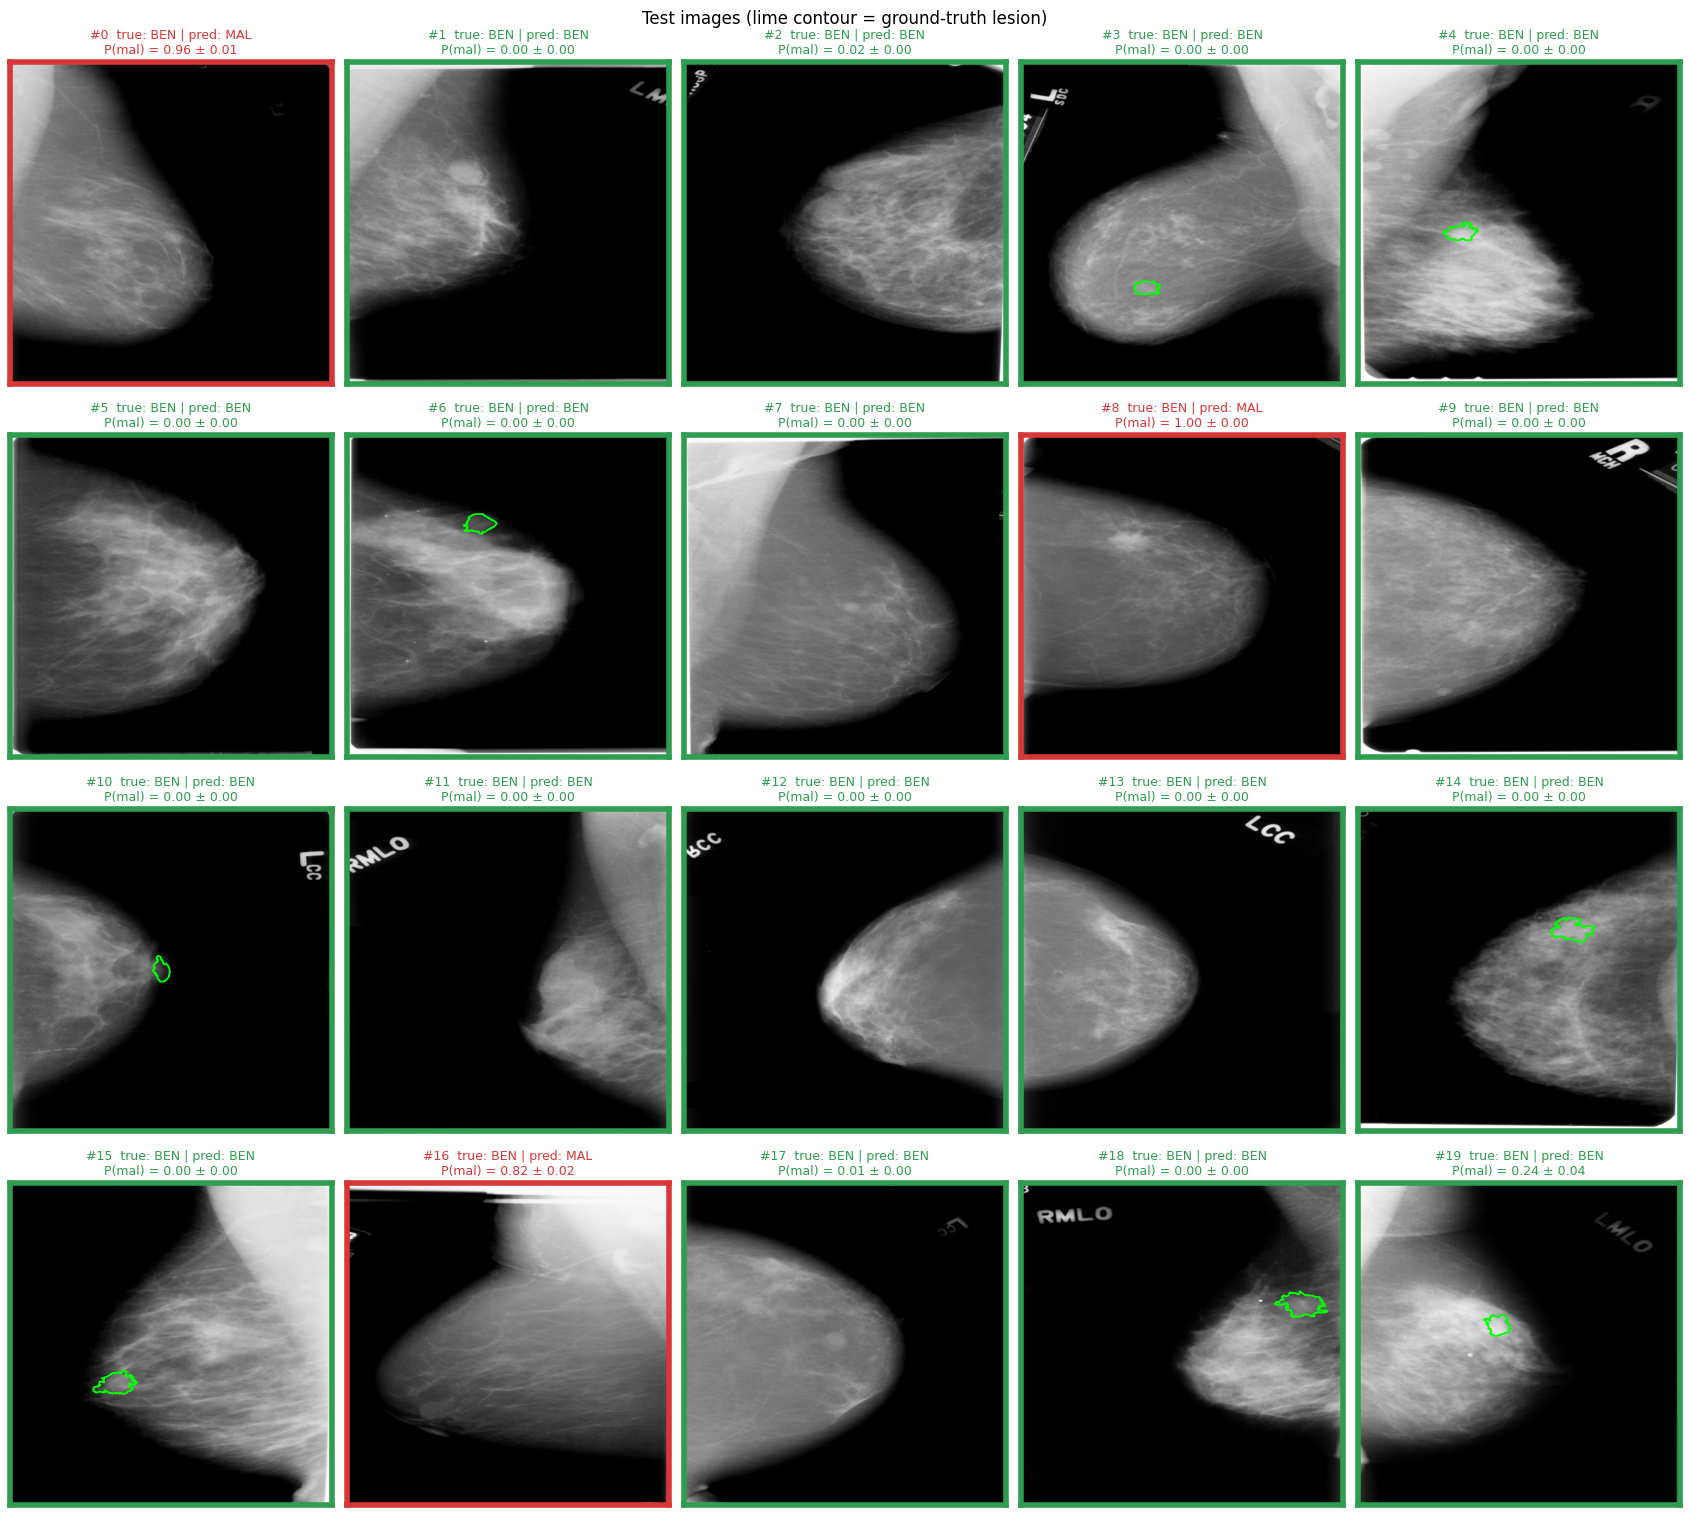

Lesion localisation on 101 images with a ground-truth mask:
  mean Dice = 0.189   mean IoU = 0.142   peak-in-lesion rate = 0.38


In [19]:
# ===================== PLOTS 3: IMAGE GALLERY + LESION LOCALISATION =====================
MEAN, STD = 0.449, 0.226
S_IMG = eval_batch["image"].shape[-1]


def _img(i): return _np(eval_batch["image"][i, 0]) * STD + MEAN          # undo normalisation
def _gt(i):  return _np(eval_batch["mask"][i, 0])
def _has_gt(i): return bool(_np(eval_batch["has_mask"][i]) > 0) and _gt(i).max() > 0.5


def _fix_axes(a):
    a.set_xlim(-0.5, S_IMG - 0.5); a.set_ylim(S_IMG - 0.5, -0.5); a.set_xticks([]); a.set_yticks([])


def plot_gallery(p, s, y, thr=0.5, max_show=20, ncols=5, path=None):
    """Every test image with its prediction. Green frame = correct, red = wrong. Lime contour = true lesion."""
    n = min(len(y), max_show); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.9 * nrows), squeeze=False)
    for j in range(n, nrows * ncols): axes.flat[j].axis("off")
    for i in range(n):
        a = axes.flat[i]; pr = p[i] >= thr; ok = pr == bool(y[i])
        a.imshow(_img(i), cmap="gray")
        if _has_gt(i): a.contour(_gt(i), levels=[0.5], colors="lime", linewidths=1.3)
        _fix_axes(a)
        for sp in a.spines.values():
            sp.set_edgecolor("#2e9d4f" if ok else "#d93636"); sp.set_linewidth(4)
        a.set_title(f"#{i}  true: {'MAL' if y[i] else 'BEN'} | pred: {'MAL' if pr else 'BEN'}\n"
                    f"P(mal) = {p[i]:.2f} ± {s[i]:.2f}", fontsize=9, color="#2e9d4f" if ok else "#d93636")
    fig.suptitle("Test images (lime contour = ground-truth lesion)", fontsize=12)
    fig.tight_layout()
    if path: fig.savefig(path, dpi=300)
    plt.show()


def seg_scores(prob, gt, thr=0.5):
    pr, g = prob >= thr, gt > 0.5
    inter, union = (pr & g).sum(), (pr | g).sum()
    dice = _div(2 * inter, pr.sum() + g.sum())
    iou = _div(inter, union)
    hit = float(g.flat[int(prob.argmax())])          # does the model's strongest response fall inside the lesion?
    return dice, iou, hit


dice_arr = np.full(len(y_np), np.nan); iou_arr = dice_arr.copy(); hit_arr = dice_arr.copy()
for i in range(len(y_np)):
    if _has_gt(i):
        dice_arr[i], iou_arr[i], hit_arr[i] = seg_scores(pf["mask_prob"][i], _gt(i))


def plot_localization(ncols=5, path_prefix=None):
    """Auxiliary mask head: where does the model think the lesion is?"""
    n = len(y_np)
    for start in range(0, n, ncols):
        idx = list(range(start, min(start + ncols, n)))
        fig, axes = plt.subplots(2, len(idx), figsize=(3.4 * len(idx), 7.2), squeeze=False)
        for c, i in enumerate(idx):
            axes[0, c].imshow(_img(i), cmap="gray")
            if _has_gt(i): axes[0, c].contour(_gt(i), levels=[0.5], colors="lime", linewidths=1.3)
            axes[0, c].set_title(f"#{i}  ({'MAL' if y_np[i] else 'BEN'})  ground truth", fontsize=9); _fix_axes(axes[0, c])

            hm = pf["mask_prob"][i]
            axes[1, c].imshow(_img(i), cmap="gray")
            axes[1, c].imshow(hm, cmap="jet", alpha=0.45, vmin=0, vmax=max(float(hm.max()), 1e-3))
            if _has_gt(i): axes[1, c].contour(_gt(i), levels=[0.5], colors="lime", linewidths=1.3)
            t = (f"Dice {dice_arr[i]:.2f} | IoU {iou_arr[i]:.2f}\npeak in lesion: {'yes' if hit_arr[i] == 1 else 'no'}"
                 if _has_gt(i) else "no GT mask")
            axes[1, c].set_title(f"{t}\nmax prob {hm.max():.2f}", fontsize=9); _fix_axes(axes[1, c])
        axes[0, 0].set_ylabel("image"); axes[1, 0].set_ylabel("predicted lesion map")
        fig.tight_layout()
        if path_prefix: fig.savefig(f"{path_prefix}_{start // ncols + 1}.png", dpi=300)
        plt.show()


plot_gallery(p_np, s_np, y_np, THR, path="test_gallery.png")
if len(y_np) <= 20:                      # one figure per 5 images -> only for small test sets
    plot_localization(path_prefix="localization")

valid = ~np.isnan(dice_arr)
print(f"Lesion localisation on {valid.sum()} images with a ground-truth mask:")
if valid.any():
    print(f"  mean Dice = {dice_arr[valid].mean():.3f}   mean IoU = {iou_arr[valid].mean():.3f}   "
          f"peak-in-lesion rate = {hit_arr[valid].mean():.2f}")

## Per-image results table

In [20]:
# ===================== PER-IMAGE RESULTS TABLE =====================
path_arr = triage(u=s_np, p=p_np)                       # same triage rule as your risk/triage plot
per_image = pd.DataFrame({
    "idx": np.arange(len(y_np)),
    "file": [Path(f).name for f in test_df["image_path"]],
    "true": np.where(y_np == 1, "malignant", "benign"),
    "P(malignant)": p_np,
    "mc_std": s_np,
    "pred": np.where(pred_np == 1, "malignant", "benign"),
    "correct": correct,
    "entropy_total": pf["H_total"],
    "entropy_aleatoric": pf["H_alea"],
    "entropy_epistemic": pf["H_epi"],
    "triage_path": path_arr,
    "density_true": np.where(has_d, dens_true + 1, np.nan),
    "density_pred": pf["dens_pred"],
    "dice": dice_arr, "iou": iou_arr, "peak_in_lesion": hit_arr,
})
per_image.to_csv("per_image_results.csv", index=False)
per_image.round(3)

,idx,file,true,P(malignant),mc_std,pred,correct,entropy_total,entropy_aleatoric,entropy_epistemic,triage_path,density_true,density_pred,dice,iou,peak_in_lesion
0,0,1-161.jpg,benign,0.963,0.009,malignant,False,0.159,0.158,0.001,recall,2.0,2,NaN,NaN,NaN
1,1,1-243.jpg,benign,0.000,0.000,benign,True,0.000,0.000,0.000,fast-track,2.0,2,NaN,NaN,NaN
2,2,1-208.jpg,benign,0.017,0.003,benign,True,0.088,0.088,0.000,routine,3.0,3,NaN,NaN,NaN
3,3,1-067.jpg,benign,0.001,0.000,benign,True,0.004,0.004,0.000,fast-track,2.0,2,0.090,0.047,1.0
4,4,1-190.jpg,benign,0.001,0.000,benign,True,0.009,0.009,0.000,fast-track,4.0,3,0.134,0.072,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,195,1-266.jpg,malignant,0.024,0.007,benign,False,0.112,0.111,0.001,routine,2.0,2,0.000,0.000,0.0
196,196,1-019.jpg,malignant,1.000,0.000,malignant,True,0.000,0.000,0.000,recall,2.0,2,0.632,0.462,0.0
197,197,1-217.jpg,malignant,0.046,0.008,benign,False,0.186,0.185,0.001,routine,2.0,2,0.000,0.000,0.0
198,198,1-161.jpg,malignant,1.000,0.000,malignant,True,0.000,0.000,0.000,recall,2.0,2,0.822,0.698,1.0
